![](./figures/Logo.PNG)

## In this part of the tutorial, you will
* analyse first-order (main effects) and total-order (total effects) indices of Sobol' using NSE as objective function
* analyse convergence of Sobol' indices
* assess Sobol' indices for multiple objective functions

- - - 

# 4 d - Sensitivity analysis - Sobol

- - -

## 1 Introduction

### 1.1 Sobol Indices

The Sobol method is a variance-based global sensitivity analysis technique that quantifies how much of the output variance of a model can be attributed to individual input parameter or combinations of them.

What do we mean by this? We fix a set of parameters and compare how the variance in the output objective drops compared to the case in which all parameters are varied freely. When the variance drops significantly, then the parameter is having a high contribution to the overall variance and the parameter is considered important.

We can then further discriminate three different effects:
* First-order effects: The variance contribution of each parameter considered independently (i.e. when only one parameter is fixed at a time).
* Higher-order effects: Contributions from interactions between two or more parameter (i.e. when a combination of parameters is fixed).
* Total effects: The sum of all effects of one parameter (i.e. all combinations that include one parameter are fixed).

By definition, the total effects are always larger than the direct effects, as they include this term. All effects should sum to one, as all parameter combinations together should explain the full variance.

The Sobol method is highly interpretable and widely applicable but can be computationally expensive due to its reliance on numerous model evaluations to estimate the variance components accurately.

- - -

## 2 Using Sobol

**Set current working directory and import python modules**

In [1]:
import sys
sys.path.append('src/')
import hbv, VBSA, PAWN, EET
import plot_functions as pf # module to visualize the results
from sampling import AAT_sampling, AAT_sampling_extend # functions to perform the input sampling
from util import aggregate_boot # function to aggregate the bootstrap results

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as st
import logging
logger = logging.getLogger("numba")
logger.setLevel(logging.ERROR)
from ipywidgets import interact, Dropdown
from matplotlib.patches import Rectangle

# overwrite colors
plt.style.use('default')
plt.matplotlib.cm.jet = lambda _: [(0.902, 0.098, 0.294), (0.235, 0.706, 0.294), (0.263, 0.388, 0.847), (0.961, 0.510, 0.192), (0.667, 1.000, 0.765), (0.259, 0.831, 0.957), (0.663, 0.663, 0.663), (1.000, 0.882, 0.098), (0.941, 0.196, 0.902), (0.980, 0.745, 0.831), (0.275, 0.600, 0.565), (0.604, 0.388, 0.141), (0.863, 0.745, 1.000)]


def calc_nse(obs, sim):
    """
    Calculate the Nash-Sutcliffe Efficiency (NSE) for model evaluation.
    The NSE ranges from zero to one, with one being optimal.
    """
    r_nse = np.corrcoef(obs, sim)[0][1] 
    alpha_nse = np.divide(np.std(sim), np.std(obs))
    beta_nse = np.divide(np.subtract(np.mean(sim), np.mean(obs)), np.std(obs))
    nse = 2 * alpha_nse * r_nse - np.square(alpha_nse) - np.square(beta_nse)
    return nse

def calc_rmse(obs, sim):
    """
    Calculate the Root Mean Square Error (RMSE) between observed and simulated values.
    The RMSE ranges from zero to infinity.
    """
    return np.sqrt(np.mean((obs - sim)**2))

def calc_bias(obs, sim):
    """
    Compute the mean bias (mean difference) between observed and simulated values.
    """
    return np.mean(np.subtract(obs, sim))

def calc_corr(obs, sim):
    """
    Calculate the correlation Pearson coefficient between observed and simulated values.
    """
    return np.corrcoef(obs, sim)[0,1]

def hbv_and_one_obj_fun(par, precip, temp, evap, runoff_obs, n_days, obj_fun):
    """
    Run HBV model and evaluate it using a single objective function.
    """
    runoff_sim, _, _ = hbv.run_hbv(precip, temp, evap, par)
    errors = obj_fun(runoff_obs[n_days:], runoff_sim[n_days:])
    return errors, runoff_sim[n_days:]

def hbv_and_three_obj_fun(par, precip, temp, evap, runoff_obs, n_days, obj_fun1, obj_fun2, obj_fun3):
    """
    Simulate runoff using HBV and evaluate with three objective functions.
    """
    runoff_sim, _, _ = hbv.run_hbv(precip, temp, evap, par)
    errors = np.nan * np.ones((3,))
    errors[0] = obj_fun1(runoff_obs[n_days:], runoff_sim[n_days:])
    errors[1] = obj_fun2(runoff_obs[n_days:], runoff_sim[n_days:])
    errors[2] = obj_fun3(runoff_obs[n_days:], runoff_sim[n_days:])
    return errors, runoff_sim[n_days:]

def sort_legend_by(order, **kwargs):

    # grab the legend handles and labels
    handles = plt.gca().legend_.legend_handles
    labels  = [label._text for label in plt.gca().legend_.texts]

    # sort both handles and labels
    handles = np.array(handles)[order]
    labels  = np.array(labels)[order]

    # set the handles of the legend
    plt.gca().legend(handles, labels, **kwargs)

plt.sort_legend_by = sort_legend_by

**Read Catchment File, Define Parameter Bounds**

In [2]:
# DO NOT ALTER! code to select the catchment

catchment_names = ["Narraguagus River, Maine", "Myakka River, FL", "Shoshnone River, WY"]
dropdown = Dropdown(
    options=catchment_names,
    value=catchment_names[0],
    description='Catchment:',
    disabled=False)

display(dropdown)

Dropdown(description='Catchment:', options=('Narraguagus River, Maine', 'Myakka River, FL', 'Shoshnone River, …

In [14]:
file_dic = {"Narraguagus River, Maine": "01022500", "Myakka River, FL": "02298608", "Shoshnone River, WY": "06280300"}

def load_catchment_data(catchment_name):

    start_date = '2000-10-01'
    end_date   = '2004-09-30'

    gauge_id = file_dic[catchment_name]
    df = pd.read_csv(f"data/{gauge_id}.txt", sep=r"\s+")
    df['Date'] = pd.to_datetime(df[['YR', 'MNTH', 'DY', 'HR']].astype(str).agg('-'.join, axis=1), format='%Y-%m-%d-%H')
    df['Date'] = df.Date.map(lambda x: x.to_pydatetime())
    df = df.set_index('Date')
    df = df.drop(["YR", "MNTH", "DY", "HR"], axis=1)
    df = df.replace(-999, None)
    df = df[["SWE", "PRCP", "PET", "OBS_RUN", "TAIR"]]
    df.columns = ["Snow [mm/day]", "P [mm/day]", "PET [mm/day]", "Q [mm/day]", "T [C]"]

    return df[start_date:end_date].reset_index()

catchment_name = dropdown.value
df = load_catchment_data(catchment_name)

# Prepare the data intput for both models
P = df["P [mm/day]"].to_numpy()
PET = df["PET [mm/day]"].to_numpy()
T = df["T [C]"].to_numpy()
Q_obs = df["Q [mm/day]"].to_numpy()

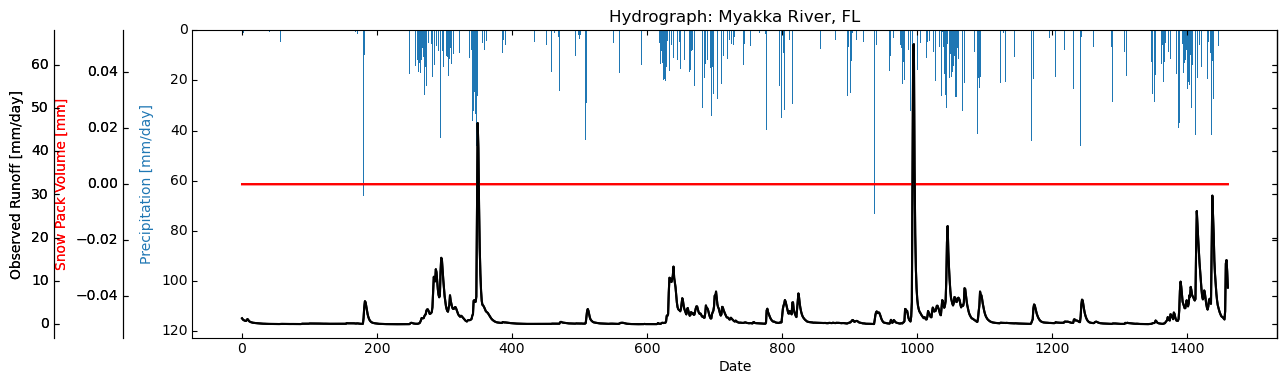

In [15]:
# number of spinup days before the evaluation period
n_spinup_days = 365
lower, upper = hbv.param_bounds.T
ranges = np.stack([lower, upper], axis=1)
parameter_names = hbv.param_names.tolist()
n_parameters = len(hbv.param_names)

def multiaxis_plot(n, side="left", offset=50, **kwargs):

    from mpl_toolkits.axes_grid1 import host_subplot
    from mpl_toolkits import axisartist

    fig  = plt.figure(**kwargs)
    host = host_subplot(111, figure=fig, axes_class=axisartist.Axes)
    axs  = [host]

    offset = -offset if side == "left" else offset
    for i in range(n - 1):
        ax = host.twinx()
        ax.axis[side] = ax.new_fixed_axis(loc=side, offset=(offset * (i + 1), 0))
        ax.axis[side].toggle(all=True)
        fig.add_axes(ax)
        axs.append(ax)

    return fig, axs if side == "right" else axs[::-1]

fig, axs = multiaxis_plot(3, figsize=(14, 4))
plt.sca(axs[0])
plt.plot(df.index, Q_obs, color="black", label="Observed")
plt.ylabel("Observed Runoff [mm/day]", color="black")
plt.sca(axs[1])
plt.plot(df.index, df["Snow [mm/day]"], color="red", label="Snow Pack Volume")
plt.ylabel("Snow Pack Volume [mm]", color="red")
plt.sca(axs[2])
plt.bar(df.index, P, label="Precipitation", color="C0", linestyle="--")
plt.ylabel("Precipitation [mm/day]", color="C0")
plt.xlabel("Date")
plt.gca().invert_yaxis()
plt.title("Hydrograph: " + list(file_dic.keys())[dropdown.index])
plt.show()

- - -

### 2.1 Using the Sobol method

#### 2.1.1 Analysing main effects, total effects and interactions

**Get samples**

In [16]:
# define distribution
distr_fun = st.uniform # uniform distribution
distr_par = [np.nan] * n_parameters
for i in range(n_parameters):
    distr_par[i] = [lower[i], upper[i] - lower[i]]
    
sampling_strategy = "lhs" # define the sampling strategy
n_samples = 2000

parameter_sets = AAT_sampling(sampling_strategy, n_parameters, distr_fun, distr_par, 2*n_samples)
parameter_sets_A, parameter_sets_B, parameter_sets_C = VBSA.vbsa_resampling(parameter_sets)

**Run the model and compute selected model output at sampled parameter sets**

In [17]:
print("Executing models (1/3): this might take a while")
errors_A = np.nan * np.ones(parameter_sets_A.shape[0]) 
for i, parameter_set_A in enumerate(parameter_sets_A):
    errors_A[i], _ = hbv_and_one_obj_fun(parameter_set_A, P, T, PET, Q_obs, n_spinup_days, calc_nse)
print("Executing models (2/3): hang on")
errors_B = np.nan * np.ones(parameter_sets_B.shape[0]) 
for i, parameter_set_B in enumerate(parameter_sets_B):
    errors_B[i], _ = hbv_and_one_obj_fun(parameter_set_B, P, T, PET, Q_obs, n_spinup_days, calc_nse)
print("Executing models (3/3): almost done")
errors_C = np.nan * np.ones(parameter_sets_C.shape[0]) 
for i, parameter_set_C in enumerate(parameter_sets_C):
    errors_C[i], _ = hbv_and_one_obj_fun(parameter_set_C, P, T, PET, Q_obs, n_spinup_days, calc_nse)
print("Computing main (first-order) and total effects")
sobol_main, sobol_total = VBSA.vbsa_indices(errors_A, errors_B, errors_C, n_parameters)

Executing models (1/3): this might take a while
Executing models (2/3): hang on
Executing models (3/3): almost done
Computing main (first-order) and total effects


**Use bootstrapping to derive confidence bounds**

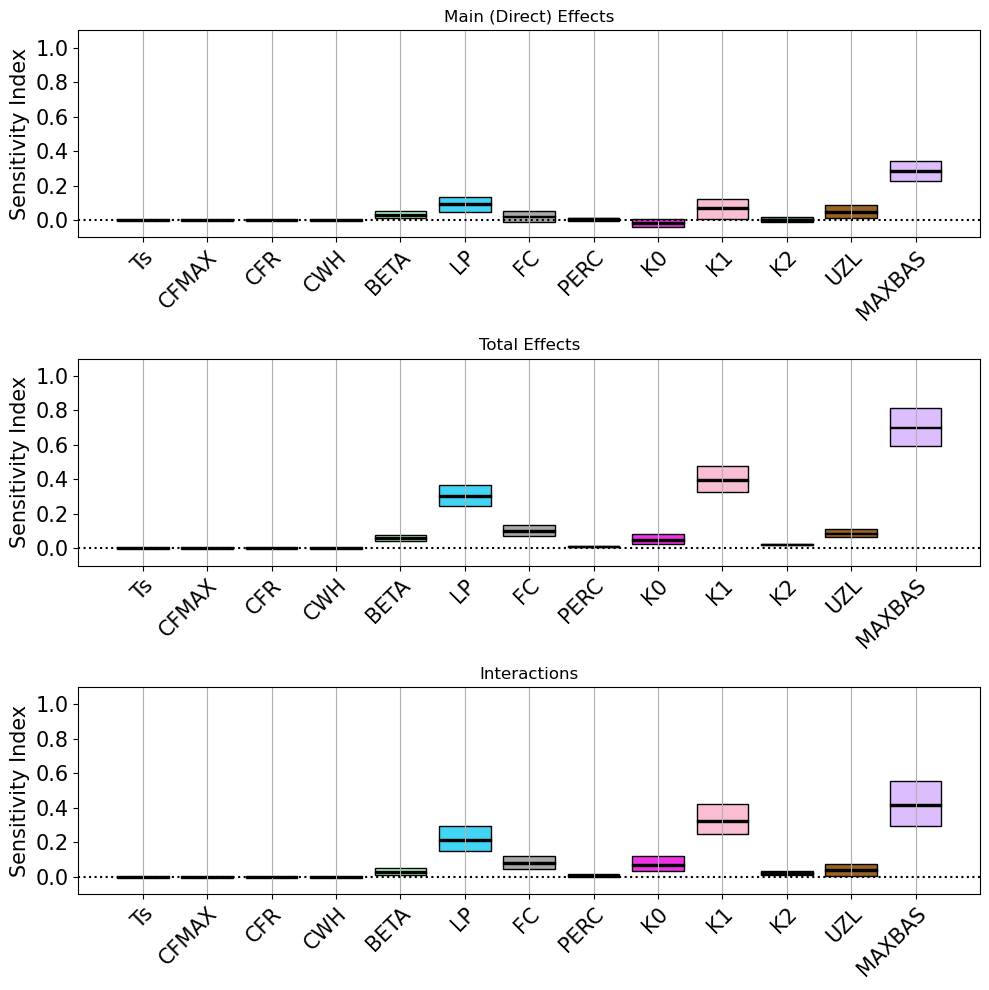

In [18]:
n_boot = 500  # bootstrap resample number
sobol_main_boot, sobol_total_boot = VBSA.vbsa_indices(errors_A, errors_B, errors_C, n_parameters, Nboot=n_boot)  # Compute sensitivity indices; each with shape (n_boot, n_parameters)
# Computing mean and confidence intervals of the sensitivity indices across the bootstrap resamples
sobol_main_m, sobol_main_lb, sobol_main_ub = aggregate_boot(sobol_main_boot) # shape (n_parameters,)
sobol_total_m, sobol_total_lb, sobol_total_ub = aggregate_boot(sobol_total_boot) # shape (n_parameters,)
sobol_inter_m, sobol_inter_lb, sobol_inter_ub = aggregate_boot(sobol_total_boot-sobol_main_boot) # shape (n_parameters,)

fig, axs = plt.subplots(3, 1, figsize=(10, 10), sharey=True)

plt.sca(axs[0])
plt.title("Main (Direct) Effects")
pf.boxplot1(sobol_main_m, S_lb=sobol_main_lb, S_ub=sobol_main_ub, X_Labels=parameter_names, Y_Label='Sensitivity Index')

plt.sca(axs[1])
plt.title("Total Effects")
pf.boxplot1(sobol_total_m, S_lb=sobol_total_lb, S_ub=sobol_total_ub, X_Labels=parameter_names, Y_Label='Sensitivity Index')

plt.sca(axs[2])
plt.title("Interactions")
pf.boxplot1(sobol_inter_m, S_lb=sobol_inter_lb, S_ub=sobol_inter_ub, X_Labels=parameter_names, Y_Label='Sensitivity Index')

for ax in axs:
    ax.set_xticklabels(parameter_names, rotation=45, ha='right', rotation_mode='anchor')
    for child in ax._children:
        if isinstance(child, Rectangle):
            child.set(edgecolor="black")


plt.tight_layout()
plt.show()

<div style="background:#e0f2fe; padding: 1%; border:1mm solid SkyBlue; color:black">
    <h4><span>&#129300 </span>Task I: Understanding the Sobol Method</h4>
    Above you will find the direct and total Sobol indices as well as their interactions for the 13 paramters of the HBV model. As the Sobol analysis is quite computationally intensive, we have selected a fixed number of model evaluations here. However, if you want to experiment with different sample sizes, you can change the `n_samples` variable above and rerun the code.
    <ol>
        <li>Which parameters has the highest direct (total, interaction) effect?</li>
        <li>Consider where confidence bounds overlap. Do you have to be careful with your interpretation?</li>
        <li>Compare these results to the Elementary Effects Analysis from the last tutorial. Are the results similar? What differences can you spot?</li>
    </ol>
</div>

_DOUBLE CLICK TO ANSWER HERE_

<div style="background:#e0f2fe; padding: 1%; border:1mm solid SkyBlue; color:black">
</div>

#### 2.1.3 Sobol with multiple objective functions

**Using multiple objective functions (RMSE, bias, correlation)**

In [19]:
print("Executing models (1/3): this might take a while")
errors_A_mulobj = np.nan * np.ones((parameter_sets_A.shape[0], 3))
for i, parameter_set_A in enumerate(parameter_sets_A):
    (errors_A_mulobj[i,0], errors_A_mulobj[i,1], errors_A_mulobj[i,2]), _ = \
        hbv_and_three_obj_fun(parameter_set_A, P, T, PET, Q_obs, n_spinup_days, calc_rmse, calc_bias, calc_corr)
print("Executing models (2/3): wait")
errors_B_mulobj = np.nan * np.ones((parameter_sets_B.shape[0], 3))
for i, parameter_set_B in enumerate(parameter_sets_B):
    (errors_B_mulobj[i,0], errors_B_mulobj[i,1], errors_B_mulobj[i,2]), _ = \
        hbv_and_three_obj_fun(parameter_set_B, P, T, PET, Q_obs, n_spinup_days, calc_rmse, calc_bias, calc_corr)
print("Executing models (3/3): almost done")
errors_C_mulobj = np.nan * np.ones((parameter_sets_C.shape[0], 3)) 
for i, parameter_set_C in enumerate(parameter_sets_C):
    (errors_C_mulobj[i,0], errors_C_mulobj[i,1], errors_C_mulobj[i,2]), _ = \
        hbv_and_three_obj_fun(parameter_set_C, P, T, PET, Q_obs, n_spinup_days, calc_rmse, calc_bias, calc_corr)

print("Computing sensitivity indices")
n_boot = 1000
sobol_main_1, sobol_total_1 = VBSA.vbsa_indices(errors_A_mulobj[:, 0], errors_B_mulobj[:, 0], errors_C_mulobj[:, 0], n_parameters, n_boot)
sobol_main_2, sobol_total_2 = VBSA.vbsa_indices(errors_A_mulobj[:, 1], errors_B_mulobj[:, 1], errors_C_mulobj[:, 1], n_parameters, n_boot)
sobol_main_3, sobol_total_3 = VBSA.vbsa_indices(errors_A_mulobj[:, 2], errors_B_mulobj[:, 2], errors_C_mulobj[:, 2], n_parameters, n_boot)

print("Computing mean and confidence intervals of the sensitivity indices across the bootstrap resamples")
sobol_main_1_m, sobol_main_1_lb, sobol_main_1_ub = aggregate_boot(sobol_main_1) # shape (n_parameters, )
sobol_total_1_m, sobol_total_1_lb, sobol_total_1_ub = aggregate_boot(sobol_total_1) # shape (n_parameters, )
sobol_inter_1_m, sobol_inter_1_lb, sobol_inter_1_ub = aggregate_boot(sobol_total_1-sobol_main_1) # shape (n_parameters,)
sobol_main_2_m, sobol_main_2_lb, sobol_main_2_ub = aggregate_boot(sobol_main_2) # shape (n_parameters, )
sobol_total_2_m, sobol_total_2_lb, sobol_total_2_ub = aggregate_boot(sobol_total_2) # shape (n_parameters, )
sobol_inter_2_m, sobol_inter_2_lb, sobol_inter_2_ub = aggregate_boot(sobol_total_2-sobol_main_2) # shape (n_parameters,)
sobol_main_3_m, sobol_main_3_lb, sobol_main_3_ub = aggregate_boot(sobol_main_3) # shape (n_parameters, )
sobol_total_3_m, sobol_total_3_lb, sobol_total_3_ub = aggregate_boot(sobol_total_3) # shape (n_parameters, )
sobol_inter_3_m, sobol_inter_3_lb, sobol_inter_3_ub = aggregate_boot(sobol_total_3-sobol_main_3) # shape (n_parameters,)

Executing models (1/3): this might take a while
Executing models (2/3): wait
Executing models (3/3): almost done
Computing sensitivity indices
Computing mean and confidence intervals of the sensitivity indices across the bootstrap resamples


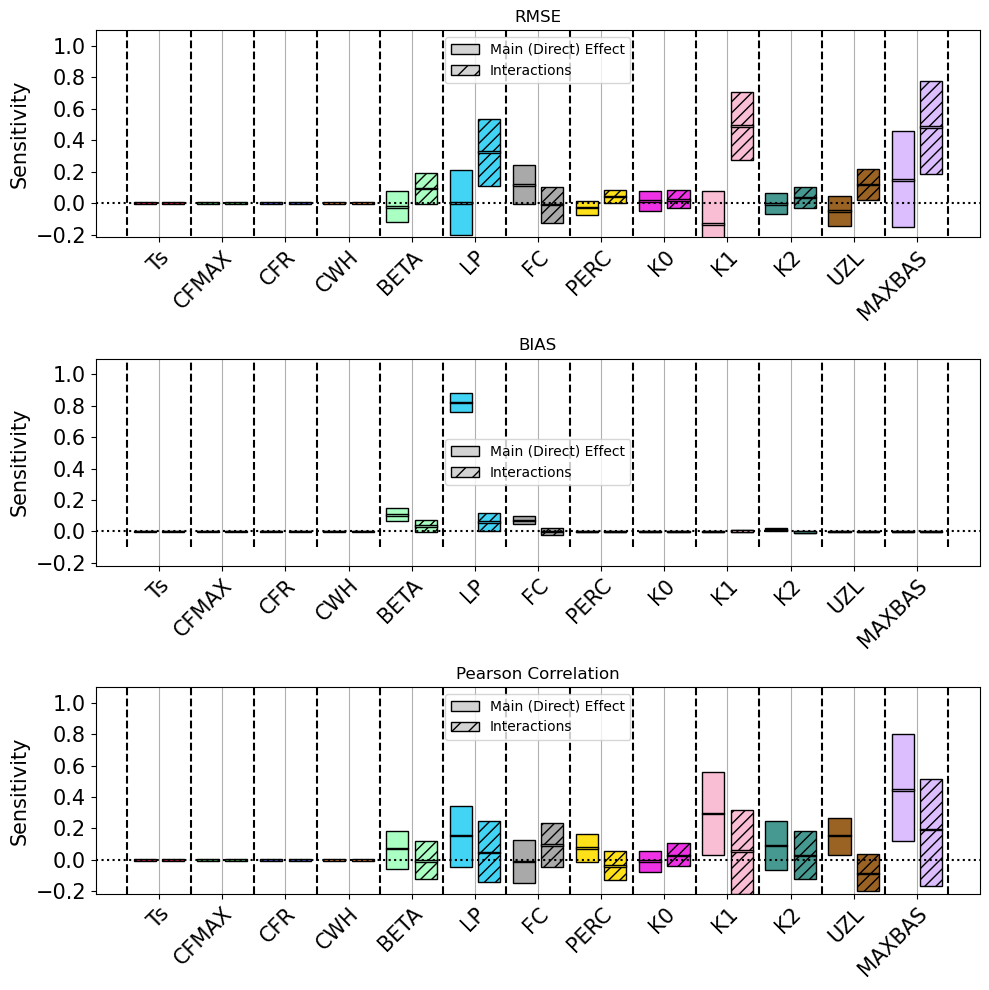

In [20]:
fig, axs = plt.subplots(3, 1, figsize=(10, 10), sharey=True)

plt.sca(axs[0])
pf.boxplot2(np.stack((sobol_main_1_m, sobol_inter_1_m)), S_lb=np.stack((sobol_main_1_lb, sobol_inter_1_lb)), S_ub=np.stack((sobol_main_1_ub, sobol_inter_1_ub)), X_Labels=parameter_names)
plt.title('RMSE')

plt.sca(axs[1])
pf.boxplot2(np.stack((sobol_main_2_m, sobol_inter_2_m)), S_lb=np.stack((sobol_main_2_lb, sobol_inter_2_lb)), S_ub=np.stack((sobol_main_2_ub, sobol_inter_2_ub)), X_Labels=parameter_names)
plt.title('BIAS')

plt.sca(axs[2])
pf.boxplot2(np.stack((sobol_main_3_m, sobol_inter_3_m)), S_lb=np.stack((sobol_main_3_lb, sobol_inter_3_lb)), S_ub=np.stack((sobol_main_3_ub, sobol_inter_3_ub)), X_Labels=parameter_names)
plt.title('Pearson Correlation')

for ax in axs:
    ax.set_xticklabels(parameter_names, rotation=45, ha='right', rotation_mode='anchor')
    ax.legend([plt.matplotlib.patches.Patch(facecolor="lightgray", edgecolor="black"), plt.matplotlib.patches.Patch(facecolor="lightgray", edgecolor="black", hatch="//")], ['Main (Direct) Effect', 'Interactions'])
    i = 0
    for child in ax._children:
        if isinstance(child, Rectangle):
            child.set(facecolor=plt.matplotlib.cm.jet(None)[i//4], hatch="///" if i % 4 == 1 else "", edgecolor="black")
            i += 1
plt.tight_layout()
plt.show()

<div style="background:#e0f2fe; padding: 1%; border:1mm solid SkyBlue; color:black">
    <h4><span>&#129300 </span>Task III: Comparing Objective Functions</h4>
    Above you find the direct and total sensitivity indices now derived for three different objective functions (RMSE, Bias and Pearson Correlation).
    <ul>
    <li>Are there differences in parameter importance across the three objective functions?</li>
    <li>Does the most important parameter change between objective functions? Why is this the case?</li>
    </ul>
</div>

_DOUBLE CLICK TO ANSWER HERE_

<div style="background:#e0f2fe; padding: 1%; border:1mm solid SkyBlue; color:black">
</div>